Zadanie 1 - Wartość funkcji i zakresy

In [11]:
import torch
import torch.nn as nn

x = torch.tensor([-5.0, -2.0, -1.0, 0.0, 1.0, 2.0, 5.0])

activations = {
    "Identity": nn.Identity(),
    "ReLU": nn.ReLU(),
    "Sigmoid": nn.Sigmoid(),
    "tanh": nn.Tanh(),
    "LeakyReLU": nn.LeakyReLU(negative_slope=0.01),
    "ELU": nn.ELU(alpha=1.0),
    "GELU": nn.GELU(),
    "Swish / SiLU": nn.SiLU(),
}

print(f"Wartości wejściowe x = {x.tolist()}\n")

for name, fn in activations.items():
    y = fn(x)
    rounded_vals = [round(val, 4) for val in y.tolist()]
    print(f"{name}: {rounded_vals}")

print("\n" + "-" * 40 + "\n")

z = torch.tensor([2.0, 1.0, 0.0])
p = nn.Softmax(dim=0)(z)

print(f"Analiza Softmax dla logitów z = {z.tolist()}")
print(f"Prawdopodobieństwa p_i: {[round(val, 4) for val in p.tolist()]}")
print(f"Czy wszystkie p_i należą do (0, 1)?: {torch.all((p > 0) & (p < 1)).item()}")
print(f"Suma p_i: {p.sum().item():.1f}")

Wartości wejściowe x = [-5.0, -2.0, -1.0, 0.0, 1.0, 2.0, 5.0]

Identity: [-5.0, -2.0, -1.0, 0.0, 1.0, 2.0, 5.0]
ReLU: [0.0, 0.0, 0.0, 0.0, 1.0, 2.0, 5.0]
Sigmoid: [0.0067, 0.1192, 0.2689, 0.5, 0.7311, 0.8808, 0.9933]
tanh: [-0.9999, -0.964, -0.7616, 0.0, 0.7616, 0.964, 0.9999]
LeakyReLU: [-0.05, -0.02, -0.01, 0.0, 1.0, 2.0, 5.0]
ELU: [-0.9933, -0.8647, -0.6321, 0.0, 1.0, 2.0, 5.0]
GELU: [-0.0, -0.0455, -0.1587, 0.0, 0.8413, 1.9545, 5.0]
Swish / SiLU: [-0.0335, -0.2384, -0.2689, 0.0, 0.7311, 1.7616, 4.9665]

----------------------------------------

Analiza Softmax dla logitów z = [2.0, 1.0, 0.0]
Prawdopodobieństwa p_i: [0.6652, 0.2447, 0.09]
Czy wszystkie p_i należą do (0, 1)?: True
Suma p_i: 1.0


Zadanie 2 - Pochodne analityczne i autograd

In [ ]:
import torch
import torch.nn as nn
import math

x = torch.tensor([-5.0, -3.0, -1.0, 0.0, 1.0, 3.0, 5.0], requires_grad=True)

def analytical_grad(name, x_t):
    x_d = x_t.detach()
    if name == "ReLU":
        return torch.where(x_d > 0, 1.0, 0.0)
    elif name == "Sigmoid":
        s = torch.sigmoid(x_d)
        return s * (1.0 - s)
    elif name == "tanh":
        return 1.0 - torch.tanh(x_d)**2
    elif name == "LeakyReLU":
        return torch.where(x_d > 0, 1.0, 0.01)
    elif name == "ELU":
        return torch.where(x_d > 0, 1.0, 1.0 * torch.exp(x_d))
    elif name == "GELU":
        Phi = 0.5 * (1.0 + torch.erf(x_d / math.sqrt(2.0)))
        phi = (1.0 / math.sqrt(2.0 * math.pi)) * torch.exp(-0.5 * x_d**2)
        return Phi + x_d * phi
    elif name == "Swish / SiLU":
        s = torch.sigmoid(x_d)
        return s + x_d * s * (1.0 - s)

activations = {
    "ReLU": nn.ReLU(),
    "Sigmoid": nn.Sigmoid(),
    "tanh": nn.Tanh(),
    "LeakyReLU": nn.LeakyReLU(negative_slope=0.01),
    "ELU": nn.ELU(alpha=1.0),
    "GELU": nn.GELU(),
    "Swish / SiLU": nn.SiLU(),
}

for name, fn in activations.items():
    y = fn(x)
    dy_autograd = torch.autograd.grad(y.sum(), x, retain_graph=True)[0]
    dy_analytic = analytical_grad(name, x)
    max_diff = torch.max(torch.abs(dy_autograd - dy_analytic)).item()

    print(f"=== {name} (Max błąd: {max_diff:.2e}) ===")
    for xi, ga, gn in zip(x.detach(), dy_autograd.detach(), dy_analytic):
        print(f"  x = {xi:>4.1f} | Autograd: {ga:>8.5f} | Analitycznie: {gn:>8.5f}")

=== ReLU (Max błąd: 0.00e+00) ===
  x = -5.0 | Autograd:  0.00000 | Analitycznie:  0.00000
  x = -3.0 | Autograd:  0.00000 | Analitycznie:  0.00000
  x = -1.0 | Autograd:  0.00000 | Analitycznie:  0.00000
  x =  0.0 | Autograd:  0.00000 | Analitycznie:  0.00000
  x =  1.0 | Autograd:  1.00000 | Analitycznie:  1.00000
  x =  3.0 | Autograd:  1.00000 | Analitycznie:  1.00000
  x =  5.0 | Autograd:  1.00000 | Analitycznie:  1.00000
=== Sigmoid (Max błąd: 0.00e+00) ===
  x = -5.0 | Autograd:  0.00665 | Analitycznie:  0.00665
  x = -3.0 | Autograd:  0.04518 | Analitycznie:  0.04518
  x = -1.0 | Autograd:  0.19661 | Analitycznie:  0.19661
  x =  0.0 | Autograd:  0.25000 | Analitycznie:  0.25000
  x =  1.0 | Autograd:  0.19661 | Analitycznie:  0.19661
  x =  3.0 | Autograd:  0.04518 | Analitycznie:  0.04518
  x =  5.0 | Autograd:  0.00665 | Analitycznie:  0.00665
=== tanh (Max błąd: 2.98e-08) ===
  x = -5.0 | Autograd:  0.00018 | Analitycznie:  0.00018
  x = -3.0 | Autograd:  0.00987 | Analit

Zadanie 3 - Wizualizacja aktywacji i gradientów

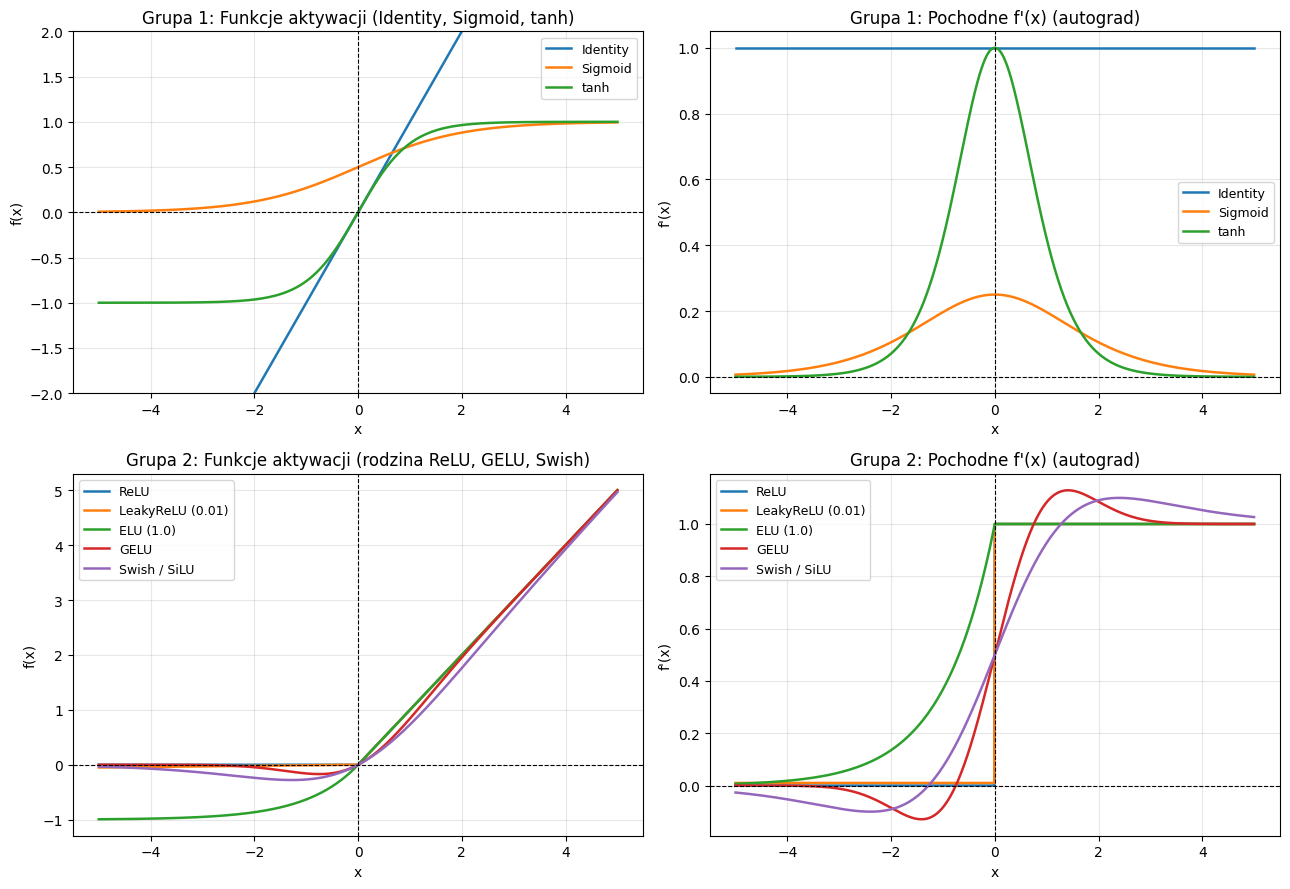

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

x = torch.linspace(-5, 5, 1001, requires_grad=True)

group_bounded = {
    "Identity": nn.Identity(),
    "Sigmoid": nn.Sigmoid(),
    "tanh": nn.Tanh(),
}

group_modern = {
    "ReLU": nn.ReLU(),
    "LeakyReLU (0.01)": nn.LeakyReLU(negative_slope=0.01),
    "ELU (1.0)": nn.ELU(alpha=1.0),
    "GELU": nn.GELU(),
    "Swish / SiLU": nn.SiLU(),
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for name, fn in group_bounded.items():
    y = fn(x)
    dy_dx = torch.autograd.grad(y.sum(), x, retain_graph=True)[0]
    axes[0, 0].plot(x.detach(), y.detach(), label=name, linewidth=1.8)
    axes[0, 1].plot(x.detach(), dy_dx.detach(), label=name, linewidth=1.8)

axes[0, 0].set_ylim(-2, 2)
axes[0, 0].set_title("Grupa 1: Funkcje aktywacji (Identity, Sigmoid, tanh)")
axes[0, 1].set_title("Grupa 1: Pochodne f'(x) (autograd)")

for name, fn in group_modern.items():
    y = fn(x)
    dy_dx = torch.autograd.grad(y.sum(), x, retain_graph=True)[0]
    axes[1, 0].plot(x.detach(), y.detach(), label=name, linewidth=1.8)
    axes[1, 1].plot(x.detach(), dy_dx.detach(), label=name, linewidth=1.8)

axes[1, 0].set_title("Grupa 2: Funkcje aktywacji (rodzina ReLU, GELU, Swish)")
axes[1, 1].set_title("Grupa 2: Pochodne f'(x) (autograd)")

for row in range(2):
    axes[row, 0].set_ylabel("f(x)")
    axes[row, 1].set_ylabel("f'(x)")
    for col in range(2):
        axes[row, col].set_xlabel("x")
        axes[row, col].grid(True, alpha=0.3)
        axes[row, col].axhline(0, color='black', linewidth=0.8, linestyle='--')
        axes[row, col].axvline(0, color='black', linewidth=0.8, linestyle='--')
        axes[row, col].legend(fontsize=9)

plt.tight_layout()
plt.show()

Zadanie 4 - Klasyfikacja binarna z różnymi aktywacjami

Wyniki na zbiorze testowym (średnia ± odchylenie z 3 ziaren losowości):

- ReLU: Loss = 0.1700 (±0.0013), Acc = 92.50% (±0.20%), Czas = 0.6413s
- tanh: Loss = 0.1697 (±0.0016), Acc = 92.50% (±0.20%), Czas = 0.4885s
- GELU: Loss = 0.1699 (±0.0017), Acc = 92.50% (±0.20%), Czas = 0.5184s
- Swish / SiLU: Loss = 0.1678 (±0.0002), Acc = 92.58% (±0.12%), Czas = 0.6285s


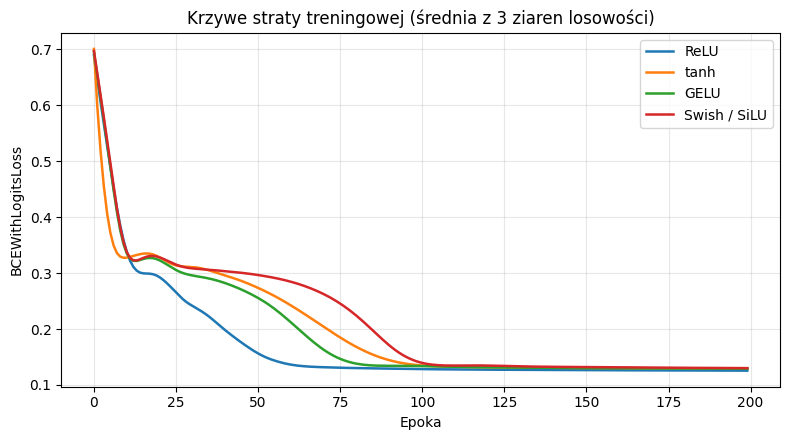

In [12]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_moons(n_samples=2000, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

class BinaryMLP(nn.Module):
    def __init__(self, activation_fn):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            activation_fn,
            nn.Linear(32, 32),
            activation_fn,
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

activations_to_test = {
    "ReLU": lambda: nn.ReLU(),
    "tanh": lambda: nn.Tanh(),
    "GELU": lambda: nn.GELU(),
    "Swish / SiLU": lambda: nn.SiLU(),
}

seeds = [42, 100, 2026]
epochs = 200
lr = 0.01

results = {name: {"test_loss": [], "test_acc": [], "time": [], "curves": []} for name in activations_to_test}

for name, act_builder in activations_to_test.items():
    for seed in seeds:
        torch.manual_seed(seed)
        np.random.seed(seed)

        model = BinaryMLP(act_builder())
        criterion = nn.BCEWithLogitsLoss()
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

        loss_curve = []
        start_time = time.perf_counter()

        model.train()
        for epoch in range(epochs):
            optimizer.zero_grad()
            logits = model(X_train_t)
            loss = criterion(logits, y_train_t)
            loss.backward()
            optimizer.step()
            loss_curve.append(loss.item())

        elapsed = time.perf_counter() - start_time

        model.eval()
        with torch.no_grad():
            test_logits = model(X_test_t)
            test_loss = criterion(test_logits, y_test_t).item()
            probs = torch.sigmoid(test_logits)
            preds = (probs >= 0.5).float()
            acc = (preds == y_test_t).float().mean().item() * 100.0

        results[name]["test_loss"].append(test_loss)
        results[name]["test_acc"].append(acc)
        results[name]["time"].append(elapsed)
        results[name]["curves"].append(loss_curve)

print("Wyniki na zbiorze testowym (średnia ± odchylenie z 3 ziaren losowości):\n")
for name, res in results.items():
    l_m, l_s = np.mean(res["test_loss"]), np.std(res["test_loss"])
    a_m, a_s = np.mean(res["test_acc"]), np.std(res["test_acc"])
    t_m = np.mean(res["time"])
    print(f"- {name}: Loss = {l_m:.4f} (±{l_s:.4f}), Acc = {a_m:.2f}% (±{a_s:.2f}%), Czas = {t_m:.4f}s")

plt.figure(figsize=(8, 4.5))
for name, res in results.items():
    mean_curve = np.mean(res["curves"], axis=0)
    plt.plot(mean_curve, label=name, linewidth=1.8)
plt.title("Krzywe straty treningowej (średnia z 3 ziaren losowości)")
plt.xlabel("Epoka")
plt.ylabel("BCEWithLogitsLoss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Zadanie 5 - Softmax i klasyfikacja wieloklasowa

In [13]:
import torch
import torch.nn as nn
import math
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def manual_softmax(z_list, T=1.0):
    exps = [math.exp(val / T) for val in z_list]
    sum_exps = sum(exps)
    return [val / sum_exps for val in exps]

for z_vals in [[2.0, 1.0, 0.0], [4.0, 1.0, 0.0]]:
    p_manual = manual_softmax(z_vals)
    p_torch = nn.Softmax(dim=0)(torch.tensor(z_vals)).tolist()
    print(f"Logity z = {z_vals}:")
    print(f"  Ręcznie: {[round(x, 4) for x in p_manual]}")
    print(f"  PyTorch: {[round(x, 4) for x in p_torch]}")

z_base = [2.0, 1.0, 0.0]
print("\n--- Wpływ temperatury T dla z = [2, 1, 0] ---")
for T in [0.5, 1.0, 2.0]:
    p_temp = manual_softmax(z_base, T=T)
    print(f"  T = {T:<3} -> p = {[round(x, 4) for x in p_temp]}")

X, y = make_blobs(n_samples=1500, centers=3, n_features=4, cluster_std=2.0, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_t = torch.tensor(scaler.fit_transform(X_train), dtype=torch.float32)
X_test_t = torch.tensor(scaler.transform(X_test), dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

def train_and_eval(use_softmax_in_model=False):
    torch.manual_seed(42)
    layers = [nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 3)]
    if use_softmax_in_model:
        layers.append(nn.Softmax(dim=1))
    model = nn.Sequential(*layers)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

    for _ in range(150):
        optimizer.zero_grad()
        out = model(X_train_t)
        loss = criterion(out, y_train_t)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        out_test = model(X_test_t)
        test_loss = criterion(out_test, y_test_t).item()
        probs = out_test if use_softmax_in_model else nn.Softmax(dim=1)(out_test)
        preds = torch.argmax(probs, dim=1)
        acc = (preds == y_test_t).float().mean().item() * 100.0
    return test_loss, acc

loss_ok, acc_ok = train_and_eval(use_softmax_in_model=False)
loss_bad, acc_bad = train_and_eval(use_softmax_in_model=True)

print("\n--- Porównanie klasyfikatorów 3-klasowych ---")
print(f"Poprawny (Logity -> CrossEntropyLoss):      Loss = {loss_ok:.4f}, Acc = {acc_ok:.2f}%")
print(f"Niezalecany (Softmax -> CrossEntropyLoss):  Loss = {loss_bad:.4f}, Acc = {acc_bad:.2f}%")

Logity z = [2.0, 1.0, 0.0]:
  Ręcznie: [0.6652, 0.2447, 0.09]
  PyTorch: [0.6652, 0.2447, 0.09]
Logity z = [4.0, 1.0, 0.0]:
  Ręcznie: [0.9362, 0.0466, 0.0171]
  PyTorch: [0.9362, 0.0466, 0.0171]

--- Wpływ temperatury T dla z = [2, 1, 0] ---
  T = 0.5 -> p = [0.8668, 0.1173, 0.0159]
  T = 1.0 -> p = [0.6652, 0.2447, 0.09]
  T = 2.0 -> p = [0.5065, 0.3072, 0.1863]

--- Porównanie klasyfikatorów 3-klasowych ---
Poprawny (Logity -> CrossEntropyLoss):      Loss = 0.0187, Acc = 100.00%
Niezalecany (Softmax -> CrossEntropyLoss):  Loss = 0.5769, Acc = 100.00%


Zadanie 6 -  Wpływ parametrów α i β

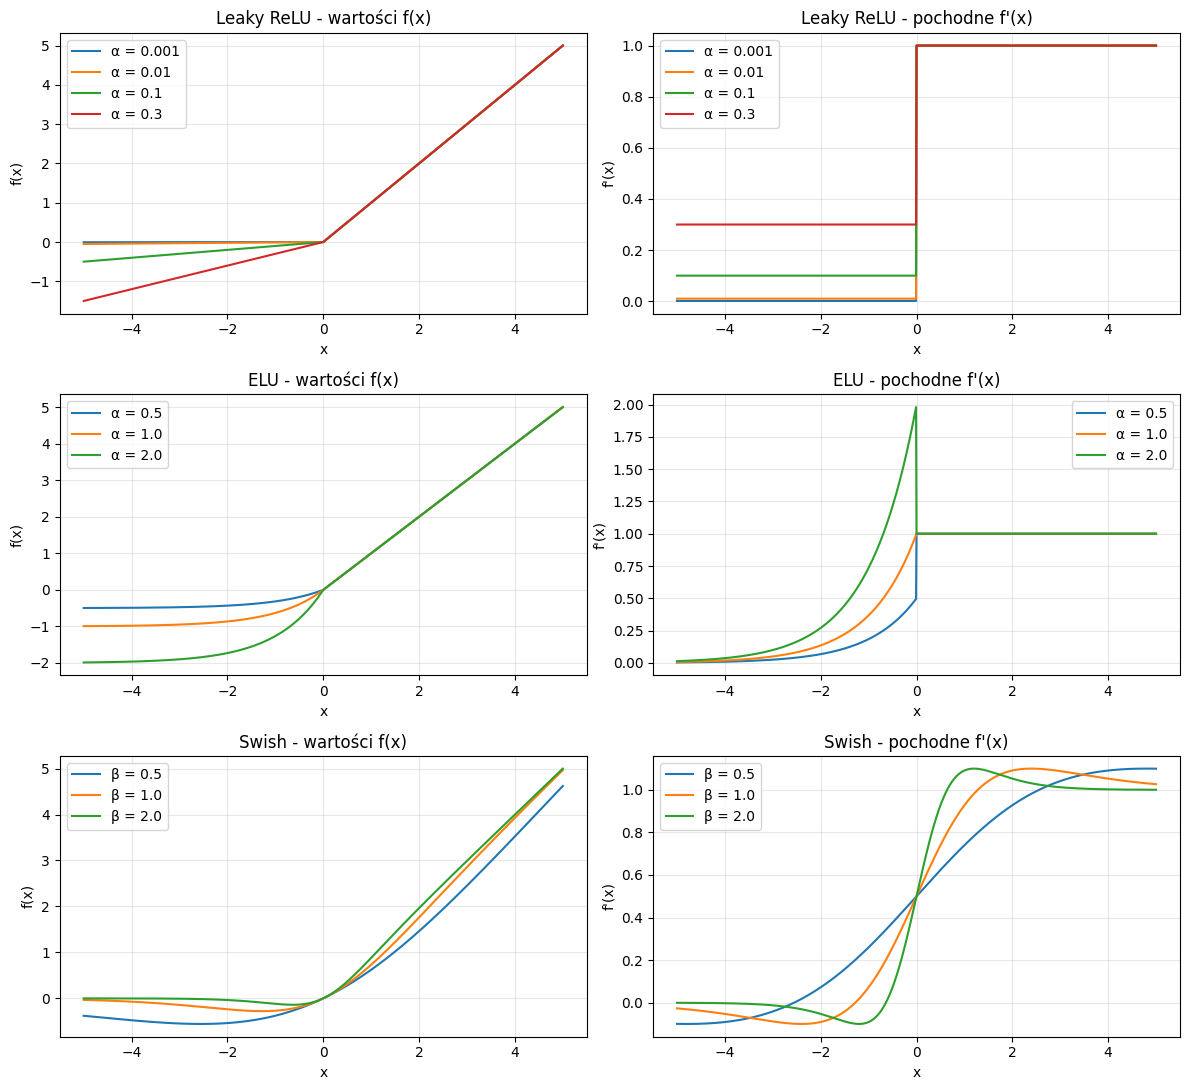

In [14]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

x = torch.linspace(-5, 5, 1001, requires_grad=True)

fig, axes = plt.subplots(3, 2, figsize=(12, 11))

for alpha in [0.001, 0.01, 0.1, 0.3]:
    fn = nn.LeakyReLU(negative_slope=alpha)
    y = fn(x)
    dy = torch.autograd.grad(y.sum(), x, retain_graph=True)[0]
    axes[0, 0].plot(x.detach(), y.detach(), label=f"α = {alpha}")
    axes[0, 1].plot(x.detach(), dy.detach(), label=f"α = {alpha}")

axes[0, 0].set_title("Leaky ReLU - wartości f(x)")
axes[0, 1].set_title("Leaky ReLU - pochodne f'(x)")

for alpha in [0.5, 1.0, 2.0]:
    fn = nn.ELU(alpha=alpha)
    y = fn(x)
    dy = torch.autograd.grad(y.sum(), x, retain_graph=True)[0]
    axes[1, 0].plot(x.detach(), y.detach(), label=f"α = {alpha}")
    axes[1, 1].plot(x.detach(), dy.detach(), label=f"α = {alpha}")

axes[1, 0].set_title("ELU - wartości f(x)")
axes[1, 1].set_title("ELU - pochodne f'(x)")

for beta in [0.5, 1.0, 2.0]:
    y = x * torch.sigmoid(beta * x)
    dy = torch.autograd.grad(y.sum(), x, retain_graph=True)[0]
    axes[2, 0].plot(x.detach(), y.detach(), label=f"β = {beta}")
    axes[2, 1].plot(x.detach(), dy.detach(), label=f"β = {beta}")

axes[2, 0].set_title("Swish - wartości f(x)")
axes[2, 1].set_title("Swish - pochodne f'(x)")

for r in range(3):
    axes[r, 0].set_ylabel("f(x)")
    axes[r, 1].set_ylabel("f'(x)")
    for c in range(2):
        axes[r, c].set_xlabel("x")
        axes[r, c].grid(True, alpha=0.3)
        axes[r, c].legend()

plt.tight_layout()
plt.show()

Zadanie 7 - Test zgodności autograd

In [15]:
import torch
import torch.nn as nn

x = torch.tensor([-2.0, -0.5, 0.0, 1.0, 2.5], dtype=torch.float64, requires_grad=True)
fn = nn.GELU()

y = fn(x)
grad_autograd = torch.autograd.grad(y.sum(), x)[0]

h_values = [1e-2, 1e-3, 1e-4]

print("=== Test zgodności autograd vs różnica centralna dla funkcji gładkiej (GELU) ===")
for h in h_values:
    with torch.no_grad():
        grad_central = (fn(x + h) - fn(x - h)) / (2.0 * h)
        abs_error = torch.abs(grad_autograd - grad_central)
        max_err = torch.max(abs_error).item()
    print(f"Krok h = {h:<6} | Maksymalny błąd bezwzględny: {max_err:.3e}")
    for xi, ga, gc, err in zip(x, grad_autograd, grad_central, abs_error):
        print(f"  x = {xi.item():>4.1f} | Autograd: {ga.item():>10.7f} | Centralna: {gc.item():>10.7f} | Błąd: {err.item():.2e}")

x_zero = torch.tensor([0.0], dtype=torch.float64, requires_grad=True)
relu_fn = nn.ReLU()
grad_relu_auto = torch.autograd.grad(relu_fn(x_zero).sum(), x_zero)[0].item()
grad_relu_cent = ((relu_fn(x_zero + 1e-4) - relu_fn(x_zero - 1e-4)) / (2.0 * 1e-4)).item()

print("\n=== Punkt nieróżniczkowalny x = 0 dla ReLU ===")
print(f"Autograd w x=0: {grad_relu_auto:.4f} (konwencja subgradientu w PyTorch)")
print(f"Różnica centralna w x=0: {grad_relu_cent:.4f} (uśrednienie nachylenia 0 i 1)")

=== Test zgodności autograd vs różnica centralna dla funkcji gładkiej (GELU) ===
Krok h = 0.01   | Maksymalny błąd bezwzględny: 1.210e-05
  x = -2.0 | Autograd: -0.0852318 | Centralna: -0.0852318 | Błąd: 9.00e-11
  x = -0.5 | Autograd:  0.1325049 | Centralna:  0.1325159 | Błąd: 1.10e-05
  x =  0.0 | Autograd:  0.5000000 | Centralna:  0.5000000 | Błąd: 0.00e+00
  x =  1.0 | Autograd:  1.0833155 | Centralna:  1.0833034 | Błąd: 1.21e-05
  x =  2.5 | Autograd:  1.0376111 | Centralna:  1.0376127 | Błąd: 1.64e-06
Krok h = 0.001  | Maksymalny błąd bezwzględny: 1.210e-07
  x = -2.0 | Autograd: -0.0852318 | Centralna: -0.0852318 | Błąd: 8.91e-15
  x = -0.5 | Autograd:  0.1325049 | Centralna:  0.1325050 | Błąd: 1.10e-07
  x =  0.0 | Autograd:  0.5000000 | Centralna:  0.5000000 | Błąd: 0.00e+00
  x =  1.0 | Autograd:  1.0833155 | Centralna:  1.0833153 | Błąd: 1.21e-07
  x =  2.5 | Autograd:  1.0376111 | Centralna:  1.0376111 | Błąd: 1.64e-08
Krok h = 0.0001 | Maksymalny błąd bezwzględny: 1.210e-0

1. Sieć złożona z samych warstw liniowych redukuje się matematycznie do jednej warstwy afinicznej, przez co nie potrafi aproksymować zjawisk nieliniowych.   

2. Zgodnie z regułą łańcuchową, pochodna f'(z) działa jako lokalny czynnik skalujący, który decyduje, ile sygnału błędu przejdzie do warstw wcześniejszych.   

3. W Sigmoid pochodne są małe (maksymalnie 0.25) i przy mnożeniu w głębokiej sieci wygaszają sygnał (zanikający gradient). W ReLU dla x < 0 pochodna wynosi 0, co przy stale ujemnym wejściu trwale wyłącza neuron z aktualizacji (martwy neuron).   

4. Softmax jest wektorowy, bo prawdopodobieństwo jednej klasy p_i zależy od mianownika sumującego wszystkie logity w warstwie.   

5. Sigmoid: klasyfikacja binarna lub wieloetykietowa (każda klasa oceniana niezależnie). Softmax: klasyfikacja wieloklasowa (tylko jedna poprawna klasa, wyniki sumują się do 1).   

6. Moduł CrossEntropyLoss w PyTorch wewnętrznie i optymalnie numerycznie kalkuluje log-softmax. Wrzucenie mu prawdopodobieństw z wcześniejszego Softmaxu podwójnie nałożyłoby tę nieliniowość i zaburzyło uczenie.   

7. Zysk: Funkcje te są gładkie i dają niezerowy gradient dla małych wartości ujemnych, co poprawia trening głębokich sieci. Koszt: Wymagają cięższych operacji matematycznych (eksponenta, dystrybuanta) niż proste ReLU.

8. Skuteczność zależy od konkretnej architektury modelu, głębokości sieci, innych hiperparametrów i budżetu obliczeniowego. Należy to weryfikować eksperymentalnie